# Lab: Relationships Between Quantitative Features

Use a historical mammal sleep dataset to compare dreaming, non-dreaming, and total sleep. Use non-dreaming versus total sleep as the main model, then examine whether danger and predation ratings add information. Finally, investigate the nonlinear pattern between gestation time and total sleep.

Support conclusions with the plots and calculations. Explain how well a straight line follows the points and how much variation remains.

## Learning goals

- Describe whether points trend upward or downward, follow a straight or curved pattern, cluster closely around that pattern, or include unusual observations.
- Calculate correlation and interpret R-squared on the correct response scale.
- Recognize nonlinear patterns and compare original gestation with log-transformed gestation.
- Examine additional categorical features visually and compare model R-squared on the same observations.
- Check missing codes, units, category counts, and transformations.
- Distinguish improved fit to observed records from causation and performance on new data.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can answer it?
3. **Evidence:** What should we calculate and display?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete each investigation in order. Use separate cells for individual operations and add cells as needed. Give figures informative titles, named colors, and axis labels with units or transformations. Use the default point transparency and line widths. `ci=None` can omit confidence bands so the patterns and group lines are easier to compare.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code and checking every claim against the source and your output. Complete the AI-use reflection at the end.

## Dataset and context

Use the [StatLib mammal sleep data hosted by UC Berkeley](https://www.stat.berkeley.edu/~spector/s100/data/sleep.dat) and its [measurement dictionary](https://www.stat.berkeley.edu/~spector/s100/data/sleep.html). A local copy is supplied as `data/mammal_sleep.csv`.

The supplied `data/mammal_sleep.csv` contains all 62 records and 11 features, including species names and both sleep phases. One row describes a mammal species, not an individual animal or a night. The data trace to Allison and Cicchetti's 1976 study, [Sleep in mammals: ecological and constitutional correlates](https://pubmed.ncbi.nlm.nih.gov/982039/). This is a historical comparative dataset, not a random sample of all mammals; individual collection dates are not supplied.

Course preparation preserves all values and names, gives columns descriptive names, and converts the source's `-999` missing code into blank CSV fields. Use ordinary `pd.read_csv()`; blanks are recognized as missing. The terms dreaming and non-dreaming identify the study's sleep-phase measurements; they are not direct reports of an animal's subjective dream experiences.

### Data dictionary

| Feature | Meaning and units or codes |
| --- | --- |
| `species` | Species label as recorded in the historical source |
| `non_dreaming_sleep` | Non-dreaming sleep in hours per day |
| `dreaming_sleep` | Dreaming sleep in hours per day |
| `body_weight` | Body weight in kilograms |
| `brain_weight` | Brain weight in grams |
| `max_life_span` | Maximum lifespan in years |
| `gestation_time` | Gestation duration in days |
| `predation_index` | Ordered rating, 1–5: lower to higher likelihood of being preyed upon |
| `sleep_exposure_index` | Ordered rating, 1–5: more protected to more exposed sleeping conditions |
| `danger_index` | Ordered rating, 1–5: lower to higher overall danger from other animals |
| `total_sleep` | Total sleep in hours per day; sum of the two phases |

The indices are **ordinal categorical features**, even though stored as numbers. A one-point difference is not a documented equal increment of physical risk. Overall danger incorporates predation, sleep exposure, and other information, so these ratings are not independent measurements. In our models, represent rating levels as categories rather than assuming equal numerical spacing.

## Load and inspect the data

In [1]:
# Import NumPy, Pandas, Matplotlib pyplot, and Seaborn.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Read data/mammal_sleep.csv into mammals_df; blank fields are recognized as missing.
mammals_df = pd.read_csv("data/mammal_sleep.csv")

In [3]:
# Display the first five rows.
mammals_df.head()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
0,African elephant,6654.000,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3
2,Arctic Fox,3.385,44.5,NaN,NaN,12.5,14.0,60.0,1,1,1
3,Arctic ground squirrel,0.920,5.7,NaN,NaN,16.5,NaN,25.0,5,2,3
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4


In [4]:
# Display the last five rows.
mammals_df.tail()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
57,Tree hyrax,2.000,12.3,4.9,0.5,5.4,7.5,200.0,3,1,3
58,Tree shrew,0.104,2.5,13.2,2.6,15.8,2.3,46.0,3,2,2
59,Vervet,4.190,58.0,9.7,0.6,10.3,24.0,210.0,4,3,4
60,Water opossum,3.500,3.9,12.8,6.6,19.4,3.0,14.0,2,1,1
61,Yellow-bellied marmot,4.050,17.0,NaN,NaN,NaN,13.0,38.0,3,1,1


In [5]:
# Display the shape.
mammals_df.shape

(62, 11)

In [6]:
# Use .info() to inspect the data storage types and non-missing values.
mammals_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   species               62 non-null     object 
 1   body_weight           62 non-null     float64
 2   brain_weight          62 non-null     float64
 3   non_dreaming_sleep    48 non-null     float64
 4   dreaming_sleep        50 non-null     float64
 5   total_sleep           58 non-null     float64
 6   max_life_span         58 non-null     float64
 7   gestation_time        58 non-null     float64
 8   predation_index       62 non-null     int64  
 9   sleep_exposure_index  62 non-null     int64  
 10  danger_index          62 non-null     int64  
dtypes: float64(7), int64(3), object(1)
memory usage: 5.5+ KB


In [7]:
# Count missing values in every feature.
mammals_df.isnull().sum()

species                  0
body_weight              0
brain_weight             0
non_dreaming_sleep      14
dreaming_sleep          12
total_sleep              4
max_life_span            4
gestation_time           4
predation_index          0
sleep_exposure_index     0
danger_index             0
dtype: int64

**What does one row represent?**

Your answer: One row represents one mammal species, not one individual animal and not one night of sleep. The values describe that species' typical sleep pattern and other species-level measurements in this historical comparative dataset.

**Complete the table using the data dictionary, `.info()`, and `.isnull().sum()`. For data type, use categorical or quantitative. For data storage type, report the Pandas dtype. For missing values, report the count, including 0 when none are missing.**

| Feature | Data type | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `species` | categorical | object | 0 |
| `non_dreaming_sleep` | quantitative | float64 | 14 |
| `dreaming_sleep` | quantitative | float64 | 12 |
| `body_weight` | quantitative | float64 | 0 |
| `brain_weight` | quantitative | float64 | 0 |
| `max_life_span` | quantitative | float64 | 4 |
| `gestation_time` | quantitative | float64 | 4 |
| `predation_index` | categorical | int64 | 0 |
| `sleep_exposure_index` | categorical | int64 | 0 |
| `danger_index` | categorical | int64 | 0 |
| `total_sleep` | quantitative | float64 | 4 |

Your answer: The three rating indices are stored as whole numbers, but they are ordinal categories rather than measured quantities. The missing counts match the `.isnull().sum()` output.

# Investigation 1: Dreaming, non-dreaming, and total sleep

## Step 1: Question

**How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?**

Compare three relationships in hours per day: dreaming versus non-dreaming, dreaming versus total, and non-dreaming versus total. In the last comparison, use non-dreaming sleep on the horizontal axis and total sleep as the response. This is the main model for Investigation 2.

**Predict the direction and strength of each relationship. Which phase do you expect to be more strongly related to total sleep, and why?**

Your answer: I expect both phases to be positively related to total sleep, because total sleep is the sum of dreaming and non-dreaming sleep. I expect the dreaming-versus-non-dreaming relationship to be positive but only weak to moderate, since species can trade off one phase against the other. I expect non-dreaming sleep to be much more strongly related to total sleep than dreaming sleep is. Non-dreaming sleep makes up most of total sleep, so changing non-dreaming sleep changes total sleep almost one-for-one, while dreaming sleep is a smaller part of the total.

## Step 2: Data

Create `sleep_df` from records complete for `dreaming_sleep`, `non_dreaming_sleep`, `total_sleep`, `danger_index`, and `predation_index`. Use `.copy()` and keep `mammals_df` unchanged. Use this same subset in all three comparisons and in Investigation 2. How many records were removed from the dataset?

Check that sleep measurements are between 0 and 24 hours per day.

In [8]:
# Prepare sleep_df and check sample size and sleep ranges.
sleep_df = mammals_df.dropna(
    subset=[
        "dreaming_sleep",
        "non_dreaming_sleep",
        "total_sleep",
        "danger_index",
        "predation_index",
    ]
).copy()

print("Original rows:", len(mammals_df))
print("Complete rows:", len(sleep_df))
print("Rows removed:", len(mammals_df) - len(sleep_df))

sleep_df[["dreaming_sleep", "non_dreaming_sleep", "total_sleep"]].describe().round(2)

Original rows: 62
Complete rows: 48
Rows removed: 14


,dreaming_sleep,non_dreaming_sleep,total_sleep
count,48.00,48.00,48.00
mean,2.03,8.67,10.70
std,1.44,3.67,4.58
min,0.00,2.10,2.90
25%,0.90,6.25,8.15
50%,1.80,8.35,10.30
75%,2.60,11.00,13.40
max,6.60,17.90,19.90


## Step 3: Evidence

Create three labeled regression plots with `sns.regplot()`: non-dreaming sleep versus dreaming sleep, total sleep versus dreaming sleep, and total sleep versus non-dreaming sleep. In each description, the feature after “versus” goes on the horizontal axis. Calculate the correlation and simple-line R-squared for each pair. Describe the points before relying on the fitted line.

When describing a scatterplot:

- **Direction:** Do the points generally rise or fall from left to right?
- **Form:** Does the overall pattern look roughly straight, curved, or have no clear shape? This describes the arrangement of the points, not the line drawn by the plotting function.
- **Strength:** How closely do the points follow that pattern?
- **Unusual observations:** Which points are far from most of the others?

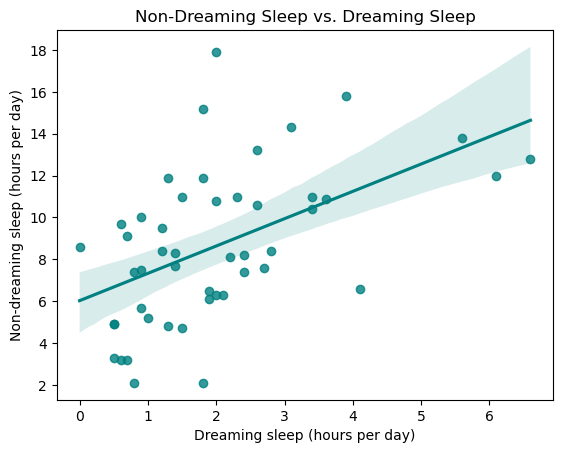

In [9]:
# Plot dreaming sleep and non-dreaming sleep.
sns.regplot(
    data=sleep_df,
    x="dreaming_sleep",
    y="non_dreaming_sleep",
    color="teal"
)
plt.title("Non-Dreaming Sleep vs. Dreaming Sleep")
plt.xlabel("Dreaming sleep (hours per day)")
plt.ylabel("Non-dreaming sleep (hours per day)")
plt.show()

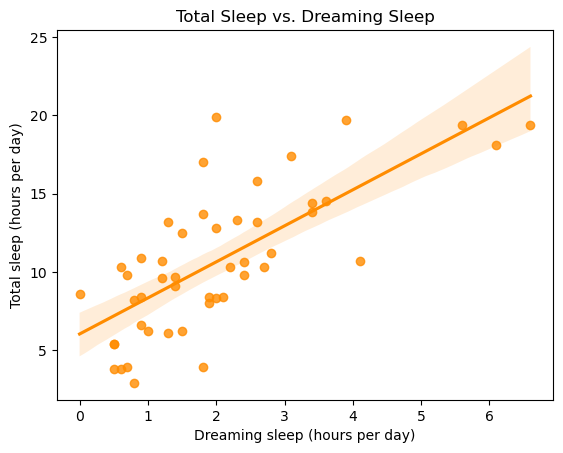

In [10]:
# Plot dreaming sleep and total sleep.
sns.regplot(
    data=sleep_df,
    x="dreaming_sleep",
    y="total_sleep",
    color="darkorange"
)
plt.title("Total Sleep vs. Dreaming Sleep")
plt.xlabel("Dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
plt.show()

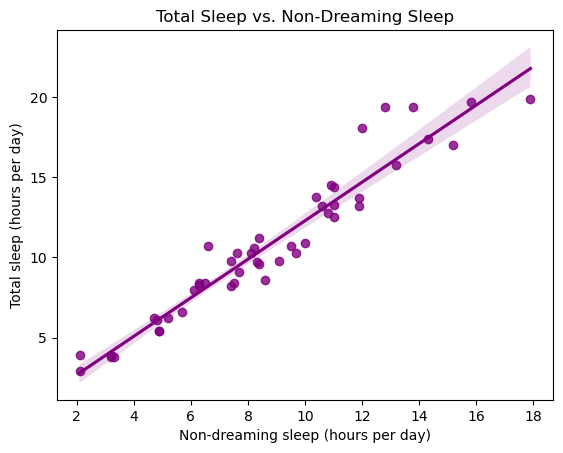

In [11]:
# Plot non-dreaming sleep and total sleep.
sns.regplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    color="purple"
)
plt.title("Total Sleep vs. Non-Dreaming Sleep")
plt.xlabel("Non-dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
plt.show()

In [12]:
# Calculate all three correlations and R-squared values.
correlation = sleep_df[["non_dreaming_sleep", "dreaming_sleep"]].corr().copy()
r = correlation.iloc[0, 1]
r_squared = (r**2) * 100
print("Non-dreaming vs. dreaming: r =", round(r, 3), "R-squared =", round(r_squared, 1), "%")

correlation = sleep_df[["dreaming_sleep", "total_sleep"]].corr().copy()
r = correlation.iloc[0, 1]
r_squared = (r**2) * 100
print("Dreaming vs. total: r =", round(r, 3), "R-squared =", round(r_squared, 1), "%")

correlation = sleep_df[["non_dreaming_sleep", "total_sleep"]].corr().copy()
r = correlation.iloc[0, 1]
r_squared = (r**2) * 100
print("Non-dreaming vs. total: r =", round(r, 3), "R-squared =", round(r_squared, 1), "%")

Non-dreaming vs. dreaming: r = 0.514 R-squared = 26.4 %
Dreaming vs. total: r = 0.727 R-squared = 52.9 %
Non-dreaming vs. total: r = 0.963 R-squared = 92.7 %


**For each plot, do the points generally rise or fall? Is their pattern roughly straight or curved, and how closely do they follow it? Identify any unusual observations. Which plot is best summarized by a straight line? Explain what its R-squared tells you about total sleep.**

Your answer: All three plots rise from left to right, so each relationship is positive. The non-dreaming–dreaming plot is only moderately tight and has a roughly straight overall pattern (r = 0.514, R-squared = 0.264). The dreaming–total plot is stronger and still roughly straight, with moderate scatter (r = 0.727, R-squared = 0.529). The non-dreaming–total plot is the tightest and most nearly straight (r = 0.963, R-squared = 0.927). One point in the non-dreaming–dreaming plot sits far to the left of the main cloud, with essentially no dreaming sleep despite a moderate amount of non-dreaming sleep; in the non-dreaming–total plot, the highest non-dreaming points are separated from most of the cluster but still follow the same upward line. The non-dreaming–total plot is best summarized by a straight line: its R-squared says that about 92.7% of the sample variation in total sleep is accounted for by the linear relationship with non-dreaming sleep, leaving about 7.3% unexplained. That is a description of this sample, not proof that non-dreaming sleep causes total sleep.

## Step 4: Check

Check that `dreaming_sleep + non_dreaming_sleep` agrees with `total_sleep` using `np.isclose()`, which allows for ordinary floating-point rounding. Display several original rows with their phase sum. Then display the three records with the longest non-dreaming sleep and locate their points on the non-dreaming versus total sleep plot. Do the plotted values agree with the records?

In [13]:
# Check the sleep-phase sum and display original measurements.
phase_sum_matches = np.isclose(
    sleep_df["dreaming_sleep"] + sleep_df["non_dreaming_sleep"],
    sleep_df["total_sleep"],
)
print("Rows where the phase sum matches total sleep:", phase_sum_matches.sum(), "of", len(sleep_df))

sleep_check = sleep_df[
    ["species", "dreaming_sleep", "non_dreaming_sleep", "total_sleep"]
].head(10).copy()
sleep_check["phase_sum"] = sleep_check["dreaming_sleep"] + sleep_check["non_dreaming_sleep"]
sleep_check

Rows where the phase sum matches total sleep: 48 of 48


,species,dreaming_sleep,non_dreaming_sleep,total_sleep,phase_sum
1,African giant pouched rat,2.0,6.3,8.3,8.3
4,Asian elephant,1.8,2.1,3.9,3.9
5,Baboon,0.7,9.1,9.8,9.8
6,Big brown bat,3.9,15.8,19.7,19.7
7,Brazilian tapir,1.0,5.2,6.2,6.2
8,Cat,3.6,10.9,14.5,14.5
9,Chimpanzee,1.4,8.3,9.7,9.7
10,Chinchilla,1.5,11.0,12.5,12.5
11,Cow,0.7,3.2,3.9,3.9
12,Desert hedgehog,2.7,7.6,10.3,10.3


In [14]:
# Inspect the three records with the longest non-dreaming sleep.
sleep_df.nlargest(3, "non_dreaming_sleep")[["species", "non_dreaming_sleep", "dreaming_sleep", "total_sleep"]]

,species,non_dreaming_sleep,dreaming_sleep,total_sleep
32,Little brown bat,17.9,2.0,19.9
6,Big brown bat,15.8,3.9,19.7
41,Owl monkey,15.2,1.8,17.0


## Step 5: Conclusion

**Research question:** How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?

**Do mammals that spend more time in dreaming sleep also tend to spend more time in non-dreaming sleep? Which phase is more strongly related to total sleep? Support your answers with the plots, correlations, and R-squared values. Did the results match your prediction?**

Your answer: Yes, mammals that spend more time in dreaming sleep also tend to spend more time in non-dreaming sleep, but the relationship is only moderate: r = 0.514 and R-squared = 0.264. The points rise together, but they are widely scattered around the line. Non-dreaming sleep is much more strongly related to total sleep than dreaming sleep is. The non-dreaming-versus-total plot has r = 0.963 and R-squared = 0.927, while the dreaming-versus-total plot has r = 0.727 and R-squared = 0.529. In other words, the non-dreaming line accounts for about 92.7% of the variation in total sleep, compared with about 52.9% for dreaming sleep. These results matched my prediction: both phases are positively related to total sleep, and non-dreaming sleep is the stronger linear predictor because it is the larger component of total sleep.

## Step 6: Limitation

**State two limitations specific to these sleep relationships. Explain why a stronger correlation is not automatically a better scientific explanation.**

Your answer: First, the data are a historical comparative sample of species, not a random sample of individual animals, and species are not independent because related species share ancestry. The analysis also drops 14 of 62 species that are missing at least one required sleep measurement, so the remaining sample may not represent all mammals. Second, total sleep is calculated as dreaming plus non-dreaming sleep, so the very strong non-dreaming-versus-total correlation is partly built into the definition. A stronger correlation is not automatically a better scientific explanation because it may reflect a definitional or mathematical relationship, a confounding variable such as body size, or overfitting to this particular sample. It does not establish causation, and it does not show that the model will predict sleep well for a new species.

# Investigation 2: Do danger and predation add information?

## Step 1: Question

**Do danger and predation categories add information about total sleep beyond non-dreaming sleep?**

**Predict whether each index will add substantial, small, or little visible information. What would you look for at comparable non-dreaming-sleep durations?**

Your answer: I predict that danger and predation will add only a small amount of visible information beyond non-dreaming sleep, because non-dreaming sleep already explains about 93% of the variation in total sleep. At comparable non-dreaming-sleep durations, I would look for vertical separation between the group lines: species with higher danger or predation ratings might have lower total sleep. I would also check whether the group lines have similar slopes and whether each group has enough observations across a shared range of non-dreaming sleep. Small groups with short ranges could produce unstable lines that look different for reasons unrelated to the rating.

## Step 2: Data

Reuse `sleep_df` and its original sleep measurements. Count records for each danger and predation rating and display a cross-tabulation of the two indices. Keep all five original levels in their natural order. Higher predation index values mean a mammal is more likely to be preyed upon. Higher danger index values mean greater overall danger from other animals.

In [15]:
# Count the records at each danger and predation level.
rating_order = [1, 2, 3, 4, 5]

print("Danger index counts")
print(sleep_df["danger_index"].value_counts().reindex(rating_order))

print("\nPredation index counts")
print(sleep_df["predation_index"].value_counts().reindex(rating_order))

Danger index counts
danger_index
1    14
2    12
3     8
4     9
5     5
Name: count, dtype: int64

Predation index counts
predation_index
1    10
2    13
3     9
4     7
5     9
Name: count, dtype: int64


In [16]:
# Cross-tabulate danger and predation ratings.
pd.crosstab(sleep_df["danger_index"], sleep_df["predation_index"]).reindex(index=rating_order, columns=rating_order)

predation_index,1,2,3,4,5
danger_index,,,,,
1,10,4,0,0,0
2,0,9,3,0,0
3,0,0,5,2,1
4,0,0,1,5,3
5,0,0,0,0,5


## Step 3: Evidence

Use `sns.lmplot()` twice on the non-dreaming–total sleep relationship, once colored by `danger_index` and once by `predation_index`. Set `hue_order=[1, 2, 3, 4, 5]`, use a named palette, and label the legend so the index direction is clear. The separate lines show group patterns; small groups may produce unstable lines. Compare groups where their non-dreaming-sleep ranges overlap.

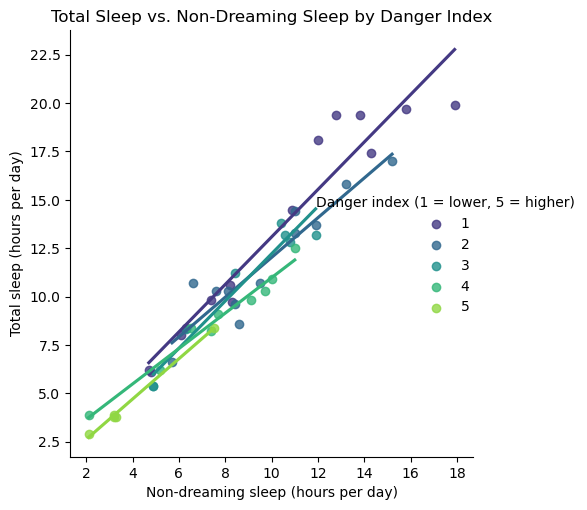

In [17]:
# Plot the non-dreaming–total sleep relationship by danger category.
danger_plot = sns.lmplot( data=sleep_df, x="non_dreaming_sleep", y="total_sleep", hue="danger_index", hue_order=rating_order, palette="viridis", ci=None,)

plt.title("Total Sleep vs. Non-Dreaming Sleep by Danger Index")
plt.xlabel("Non-dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
danger_plot._legend.set_title("Danger index (1 = lower, 5 = higher)")
plt.show()

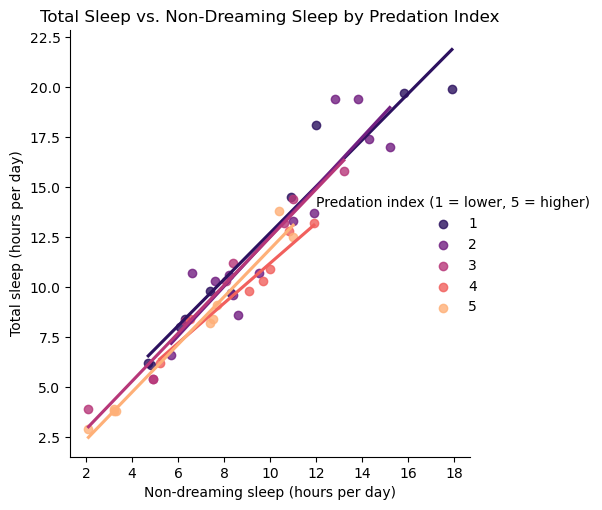

In [18]:
# Plot the non-dreaming–total sleep relationship by predation category.
predation_plot = sns.lmplot( data=sleep_df, x="non_dreaming_sleep", y="total_sleep", hue="predation_index", hue_order=rating_order, palette="magma", ci=None,)

plt.title("Total Sleep vs. Non-Dreaming Sleep by Predation Index")
plt.xlabel("Non-dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
predation_plot._legend.set_title("Predation index (1 = lower, 5 = higher)")
plt.show()

**Describe overlap and separation in each plot. How do the group sizes and available non-dreaming-sleep ranges affect your interpretation?**

Your answer: In the danger plot, the lines overlap over most of the shared range, but the highest danger group (5) sits lower than the others. Groups 1 and 2 are the largest (14 and 12 species) and span the widest non-dreaming-sleep ranges, so their lines are the most stable. Groups 3, 4, and 5 are smaller, and group 5 covers only a short range of non-dreaming sleep, so its line is short and easily influenced by a few points. In the predation plot, the lines are more mixed: groups 1, 2, and 3 overlap closely, while groups 4 and 5 are somewhat lower but are based on only seven and nine species. Because the group sizes and x-ranges differ, I should compare lines only where the groups actually overlap and avoid treating a short, steep line as strong evidence of a group difference.

### Compare model R-squared

The supplied helper follows the lecture's least-squares calculation. Read and run it; you do not need to recreate its matrix operations. `pd.get_dummies()` represents each rating with category indicators. `drop_first=True` chooses a reference level. This avoids assuming equal distances between index values.

These are **additive models**: one shared slope for the quantitative predictor and category-specific intercept adjustments. They differ from the separate group slopes in `lmplot()`. Compare the baseline, baseline plus danger, baseline plus predation, and baseline plus both, all on identical rows and the same response scale. Training R-squared cannot decrease when predictors are added to these nested models; an increase alone does not establish improved performance on new observations.

In [19]:
def calculate_r_squared(data, predictor, response, categorical_features):
    predictors = pd.get_dummies(
        data[[predictor, *categorical_features]],
        columns=categorical_features, drop_first=True, dtype=float
    )
    predictors.insert(0, "intercept", 1.0)
    x = predictors.to_numpy(dtype=float)
    y = data[response].to_numpy(dtype=float)
    fitted = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()

In [20]:
# Build and display phase_comparison for the four models.
phase_comparison = pd.Series(
    {
        "Non-dreaming only": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", []
        ),
        "Non-dreaming + danger": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", ["danger_index"]
        ),
        "Non-dreaming + predation": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", ["predation_index"]
        ),
        "Non-dreaming + both": calculate_r_squared(
            sleep_df,
            "non_dreaming_sleep",
            "total_sleep",
            ["danger_index", "predation_index"],
        ),
    },
    name="r_squared",
)

phase_comparison.round(4)

Non-dreaming only           0.9268
Non-dreaming + danger       0.9427
Non-dreaming + predation    0.9371
Non-dreaming + both         0.9515
Name: r_squared, dtype: float64

## Step 4: Check

For each danger rating, display the smallest and largest non-dreaming sleep values using `.groupby()` and `.agg(["min", "max"])`. Repeat for predation ratings.

Compare these ranges with the group plots. Use the ranges to identify where two groups actually have observations at similar non-dreaming sleep durations.

In [21]:
# Display the non-dreaming sleep range for each danger and predation rating.
print("Non-dreaming sleep range by danger index")
print(sleep_df.groupby("danger_index")["non_dreaming_sleep"].agg(["min", "max"]).reindex(rating_order))
print("\nNon-dreaming sleep range by predation index")
print(sleep_df.groupby("predation_index")["non_dreaming_sleep"].agg(["min", "max"]).reindex(rating_order))

Non-dreaming sleep range by danger index
              min   max
danger_index           
1             4.7  17.9
2             5.7  15.2
3             4.9  11.9
4             2.1  11.0
5             2.1   7.5

Non-dreaming sleep range by predation index
                 min   max
predation_index           
1                4.7  17.9
2                5.7  15.2
3                2.1  13.2
4                5.2  11.9
5                2.1  11.0


**Choose two danger groups. Over what range of non-dreaming sleep do both groups have observations? Why should you compare their lines within that shared range?**

Your answer: I will compare danger groups 1 and 5. Group 1 has non-dreaming sleep from 4.7 to 17.9 hours per day, and group 5 has non-dreaming sleep from 2.1 to 7.5 hours per day. Their shared range is therefore about 4.7 to 7.5 hours per day. Within that range both groups actually have observations, so a vertical difference between the lines is supported by data from both groups. Outside the shared range, one group's line would be extrapolated beyond its observed non-dreaming-sleep values, and with only five species in group 5 that extrapolation could easily be misleading.

## Step 5: Conclusion

**Research question:** Do danger and predation categories add information about total sleep beyond non-dreaming sleep?

**Does adding danger, predation, or both improve the model of total sleep? Report the four R-squared values and how much each changes from non-dreaming sleep alone. Are the improvements small or large? Explain how the group plots support your answer.**

Your answer: Adding either index improves the training fit only slightly. Non-dreaming sleep alone has R-squared = 0.9268. Adding danger raises it to 0.9427, an increase of 0.0159 (about 1.6 percentage points). Adding predation raises it to 0.9371, an increase of 0.0103 (about 1.0 percentage point). Adding both gives 0.9515, an increase of 0.0247 (about 2.5 percentage points). These are small improvements relative to the 92.7% already explained by non-dreaming sleep. The group plots support this: the lines mostly overlap, especially in the predation plot. The danger-5 line is visibly lower, but it is based on only five species over a short range, so that separation is uncertain. The combined model also has to estimate several category terms from a small sample. Training R-squared cannot decrease when predictors are added, so the small increases do not establish that danger or predation would improve predictions for new mammals.

## Step 6: Limitation

**Identify two limitations of this investigation.**

Your answer: First, danger and predation are ordinal ratings, not equally spaced measurements, and the two indices overlap heavily in the cross-tabulation (danger 1 is almost entirely predation 1 or 2, while danger 5 is entirely predation 5). Overall danger also incorporates predation and sleep exposure, so the indices are not independent, and their separate effects are difficult to disentangle. Second, several rating groups are small, especially danger 5 with five species, and their non-dreaming-sleep ranges are short. The group lines and the added R-squared can therefore be unstable and may reflect a few unusual species. The comparison is also observational and based on training fit, so it does not show causation or guarantee better performance on new data.

# Investigation 3: Gestation time and total sleep

## Step 1: Question

**How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?**

Gestation time is the length of a pregnancy, measured in days. We will compare it with total sleep, measured in hours per day, and see whether taking the logarithm of gestation time makes the pattern look straighter.

**Do you expect mammals with longer pregnancies to sleep more hours per day, fewer hours, or about the same amount? Explain your initial guess. You do not need prior knowledge about mammals; you will compare your prediction with the data.**

Your answer: I expect mammals with longer pregnancies to sleep fewer hours per day on average. The few large mammals I have seen so far, such as the elephants, have long pregnancies and very low total sleep, while several small mammals with short pregnancies sleep much more. I also expect the pattern to be curved rather than a straight line: a change of a few days should matter more for a short pregnancy than for a long one, so the points may fall steeply at the low end and flatten out at the high end.

## Step 2: Data

Create `gestation_df` by dropping rows missing `gestation_time`, `total_sleep`, `danger_index`, or `predation_index`, then copying the result. How many records were removed from the dataset? Do not drop rows merely because maximum lifespan is missing. Check that gestation is positive and sleep is between 0 and 24 hours per day. Create `log10_gestation_time` only after checking the inputs.

In [22]:
# Prepare gestation_df and check counts and plausible ranges.
gestation_df = mammals_df.dropna(subset=["gestation_time", "total_sleep", "danger_index", "predation_index"]).copy()

print("Original rows:", len(mammals_df))
print("Complete rows:", len(gestation_df))
print("Rows removed:", len(mammals_df) - len(gestation_df))
print(gestation_df[["gestation_time", "total_sleep"]].describe().round(2))

gestation_df["log10_gestation_time"] = np.log10(gestation_df["gestation_time"])

Original rows: 62
Complete rows: 54
Rows removed: 8
       gestation_time  total_sleep
count           54.00        54.00
mean           136.03        10.48
std            140.65         4.62
min             12.00         2.60
25%             36.75         8.05
50%             79.00        10.65
75%            195.00        13.20
max            645.00        19.90


## Step 3: Evidence

Plot sleep against gestation on original scales, then against log10 gestation, leaving sleep in hours per day. Calculate correlation and simple-line R-squared for each. These R-squared values share the same response scale and observations. Compare whether the points follow a straight or curved pattern and how widely they are scattered, as well as the numerical summaries.

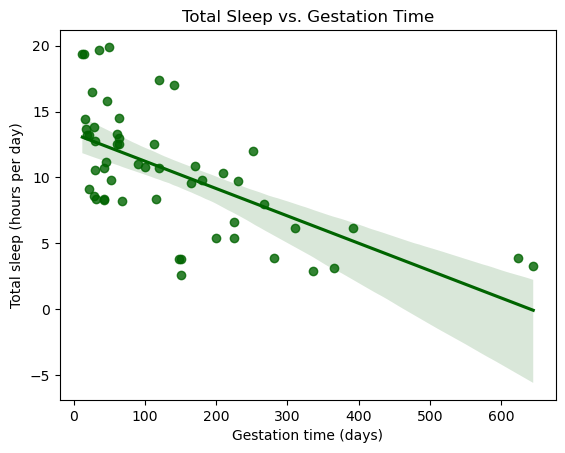

In [23]:
# Plot original gestation and sleep.
sns.regplot(data=gestation_df, x="gestation_time", y="total_sleep", color="darkgreen")

plt.title("Total Sleep vs. Gestation Time")
plt.xlabel("Gestation time (days)")
plt.ylabel("Total sleep (hours per day)")
plt.show()

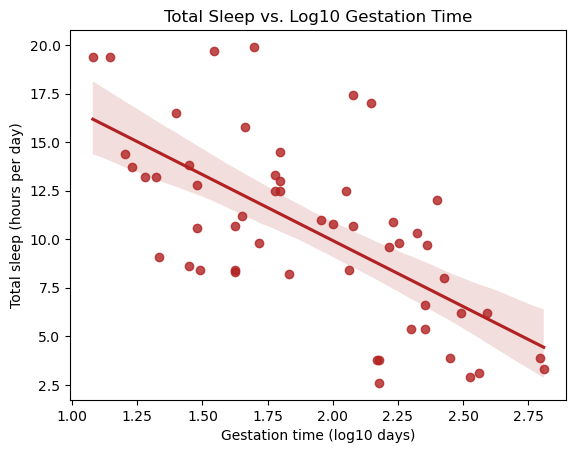

In [24]:
# Plot log gestation and sleep.
sns.regplot(data=gestation_df, x="log10_gestation_time", y="total_sleep", color="firebrick")

plt.title("Total Sleep vs. Log10 Gestation Time")
plt.xlabel("Gestation time (log10 days)")
plt.ylabel("Total sleep (hours per day)")
plt.show()

In [25]:
# Calculate the two correlations and squared correlations.
correlation = gestation_df[["gestation_time", "total_sleep"]].corr().copy()
r = correlation.iloc[0, 1]
r_squared = (r**2) * 100
print("Original gestation: r =", round(r, 3), "R-squared =", round(r_squared, 1), "%")

correlation = gestation_df[["log10_gestation_time", "total_sleep"]].corr().copy()
r = correlation.iloc[0, 1]
r_squared = (r**2) * 100
print("Log10 gestation: r =", round(r, 3), "R-squared =", round(r_squared, 1), "%")

Original gestation: r = -0.631 R-squared = 39.9 %
Log10 gestation: r = -0.664 R-squared = 44.0 %


**What changes when gestation is log-transformed? Does the transformation remove the scatter or only improve the straight-line summary modestly?**

Your answer: On the original scale the points fall from left to right, but they are bunched at low gestation times and the pattern is curved: most species have gestation under about 200 days, and a few long-gestation species stretch the horizontal axis far to the right. After the log transformation, the points are spread more evenly along the horizontal axis and the overall pattern looks straighter. The correlation changes from r = -0.631 (R-squared = 0.399) to r = -0.664 (R-squared = 0.440), so the straight-line summary improves modestly, by about 4 percentage points of explained variation. The transformation does not remove the scatter: about 56% of the variation in total sleep is still unexplained, and the vertical spread around the line remains substantial.

Reuse the group-plot and model-comparison approach from Investigation 2, now using `log10_gestation_time` as the predictor and `total_sleep` as the response. Count observations at each rating level in this subset before interpreting the group lines. Examine danger and predation separately, then compare all four additive models on `gestation_df`.

In [26]:
# Count ratings in the sleep subset.
print("Danger index counts")
print(gestation_df["danger_index"].value_counts().reindex(rating_order))

print("\nPredation index counts")
print(gestation_df["predation_index"].value_counts().reindex(rating_order))

Danger index counts
danger_index
1    16
2    12
3    10
4     9
5     7
Name: count, dtype: int64

Predation index counts
predation_index
1    12
2    14
3     9
4     7
5    12
Name: count, dtype: int64


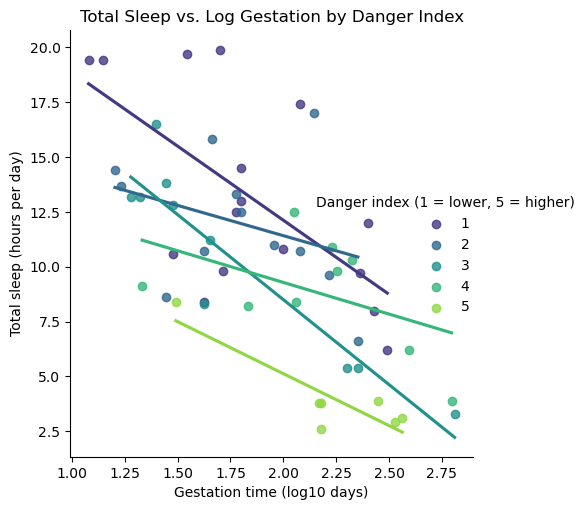

In [27]:
# Plot log gestation and sleep by danger.
gestation_danger_plot = sns.lmplot(data=gestation_df, x="log10_gestation_time", y="total_sleep", hue="danger_index", hue_order=rating_order, palette="viridis", ci=None,)

plt.title("Total Sleep vs. Log Gestation by Danger Index")
plt.xlabel("Gestation time (log10 days)")
plt.ylabel("Total sleep (hours per day)")
gestation_danger_plot._legend.set_title("Danger index (1 = lower, 5 = higher)")
plt.show()

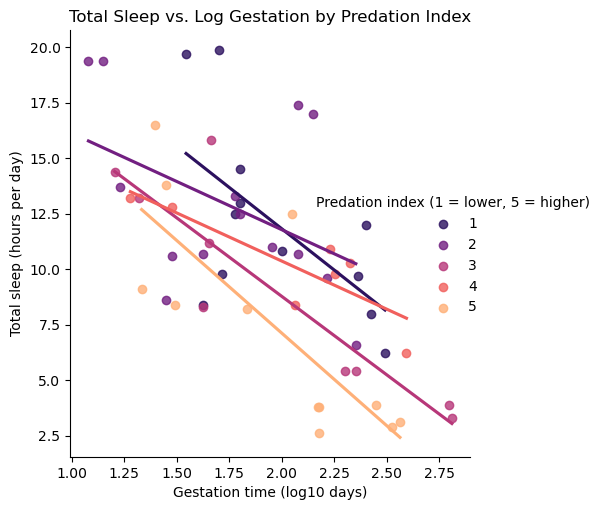

In [28]:
# Plot log gestation and sleep by predation.
gestation_predation_plot = sns.lmplot(data=gestation_df, x="log10_gestation_time", y="total_sleep", hue="predation_index", hue_order=rating_order, palette="magma", ci=None,)

plt.title("Total Sleep vs. Log Gestation by Predation Index")
plt.xlabel("Gestation time (log10 days)")
plt.ylabel("Total sleep (hours per day)")
gestation_predation_plot._legend.set_title("Predation index (1 = lower, 5 = higher)")
plt.show()

In [29]:
# Build and display sleep_comparison for the four models.
sleep_comparison = pd.Series(
    {
        "Log gestation only": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", []
        ),
        "Log gestation + danger": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", ["danger_index"]
        ),
        "Log gestation + predation": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", ["predation_index"]
        ),
        "Log gestation + both": calculate_r_squared(
            gestation_df,
            "log10_gestation_time",
            "total_sleep",
            ["danger_index", "predation_index"],
        ),
    },
    name="r_squared",
)

sleep_comparison.round(4)

Log gestation only           0.4404
Log gestation + danger       0.6542
Log gestation + predation    0.5917
Log gestation + both         0.6943
Name: r_squared, dtype: float64

## Step 4: Check

For the first five records, display gestation time, its logarithm, and `10 ** log10_gestation_time`. Does reversing the logarithm recover the original number of days?

Display the records with the shortest and longest gestation times. Find their points in both plots and compare the recorded sleep hours with their vertical positions. The horizontal positions change when gestation is transformed; the sleep measurements stay the same.

In [30]:
# Reverse the logarithm for five records and compare with the original gestation times.
gestation_check = gestation_df[
    ["species", "gestation_time", "log10_gestation_time"]
].head(5).copy()
gestation_check["recovered_gestation_time"] = 10 ** gestation_check["log10_gestation_time"]
gestation_check["matches_original"] = np.isclose(
    gestation_check["recovered_gestation_time"],
    gestation_check["gestation_time"],
)
gestation_check

,species,gestation_time,log10_gestation_time,recovered_gestation_time,matches_original
0,African elephant,645.0,2.809560,645.0,True
1,African giant pouched rat,42.0,1.623249,42.0,True
2,Arctic Fox,60.0,1.778151,60.0,True
3,Arctic ground squirrel,25.0,1.397940,25.0,True
4,Asian elephant,624.0,2.795185,624.0,True


In [31]:
# Inspect extreme gestation records.
print("Shortest gestation times")
print(
    gestation_df.nsmallest(3, "gestation_time")[
        ["species", "gestation_time", "log10_gestation_time", "total_sleep"]
    ]
)

print("\nLongest gestation times")
print(
    gestation_df.nlargest(3, "gestation_time")[
        ["species", "gestation_time", "log10_gestation_time", "total_sleep"]
    ]
)

Shortest gestation times
                species  gestation_time  log10_gestation_time  total_sleep
38  N. American opossum            12.0              1.079181         19.4
60        Water opossum            14.0              1.146128         19.4
22       Golden hamster            16.0              1.204120         14.4

Longest gestation times
            species  gestation_time  log10_gestation_time  total_sleep
0  African elephant           645.0              2.809560          3.3
4    Asian elephant           624.0              2.795185          3.9
7   Brazilian tapir           392.0              2.593286          6.2


**Did reversing the logarithm recover the original gestation times? For the shortest and longest gestation records, do both plots show the recorded total sleep values? Describe what changed between the plots and what stayed the same.**

Your answer: Yes. For the first five records, raising 10 to the power of log10_gestation_time returns the original gestation time in days, up to ordinary rounding (for example, 10^2.80956 is 645 days for the African elephant). The shortest gestation records are the North American opossum (12 days, 19.4 hours of sleep) and the water opossum (14 days, 19.4 hours). The longest are the African elephant (645 days, 3.3 hours) and the Asian elephant (624 days, 3.9 hours). Both plots show these same total-sleep values, so the vertical positions do not change. What changes is the horizontal spacing: the log scale spreads out the short gestation times and compresses the long ones, making the points easier to compare along a straight line. The transformation changes only the x-axis representation, not the observed sleep measurements or the species in the sample.

## Step 5: Conclusion

**Research question:** How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?

**Do mammals with longer gestation times tend to sleep more or less? Does using log gestation make the pattern look straighter? Do danger and predation add information? Support your answers with the plots, correlation, and R-squared values, and compare the results with your prediction.**

Your answer: Mammals with longer gestation times tend to sleep less. The original-scale correlation is r = -0.631 (R-squared = 0.399), so the line falls from left to right, but the points are curved and bunched at low gestation times. Using log10 gestation makes the pattern look straighter and slightly stronger: r = -0.664 and R-squared = 0.440. The transformation improves the straight-line summary and leaves most of the variation unexplained. Danger and predation add more information in this investigation than they did for non-dreaming sleep. Log gestation alone has R-squared = 0.440; adding danger raises it to 0.654 (+0.214), adding predation raises it to 0.592 (+0.151), and adding both raises it to 0.694 (+0.254). The danger group plot shows the high-danger group lower than the others, and the predation plot shows some separation as well, but the groups are small and the indices overlap. The negative direction and the curved original pattern matched my prediction, and the log transformation did make the pattern straighter, though it did not remove the scatter.

## Step 6: Limitation

**Identify two limitations of the gestation and sleep investigation.**

Your answer: First, this is an observational comparative dataset with one row per species, and species are not independent because of shared evolutionary history. A negative association between gestation time and total sleep does not show that longer gestation causes less sleep; body size, brain size, diet, and other traits could affect both. Second, eight of the 62 species were removed because at least one required value was missing, and the remaining sample may be biased. Gestation ranges from 12 to 645 days, and some rating groups are small, so the group lines and R-squared values are sensitive to a few species. The model comparison also uses training R-squared, which cannot decrease when predictors are added, so it does not measure performance on new data.

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: Yes. I used an AI assistant to help organize the code and draft explanations. I checked each numerical claim against the notebook's own output rather than accepting the assistant's wording. I accepted the code structure and the descriptive wording after running it, but I modified or rejected claims that went beyond the evidence, such as saying that danger or predation caused differences in sleep or that a higher R-squared proves better prediction. I also kept the limitation statements that the data are observational and that training fit is not out-of-sample performance.

## Submission checklist

- Use the supplied CSV with a relative path.
- Complete the dictionary table and every written response.
- Include a prediction and all six workflow steps for each investigation.
- Include all three sleep comparison plots, two non-dreaming–total group plots, original and log-gestation sleep plots, and two sleep group plots.
- Keep observations consistent within each comparison; report counts and investigate exclusions.
- Interpret correlation and R-squared on the correct scale, using numerical and visual evidence.
- Compare baseline, danger, predation, and combined models without claiming automatic causal or predictive improvement.
- Explain whether the patterns are straight or curved, how the log transformation changes the gestation plot, and what the analyses cannot tell us.
- Complete the AI-use reflection, restart the kernel, and run the notebook in order before submitting.